# Tweety-10 — Markov Logic Networks (MLN)

**Navigation** : [← Tweety-9-Préférences](Tweety-09-Preferences-Python.ipynb) | [Index](Tweety-01-Setup-Python.ipynb) | [README](README.md)

***

## Objectifs pedagogiques

1. Comprendre ce qu'est un **Markov Logic Network** : une formule de logique du premier ordre **associee a un poids**
2. Distinguer règle **stricte** (contrainte dure) et règle **pondérée** (tendance statistique)
3. Calculer la **probabilite marginale** d'un atome via un reasoner MLN
4. Comprendre comment les poids **modelent la croyance** (spectre logique ↔ statistique)
5. Resoudre le **paradoxe des exceptions** (le pingouin qui ne vole pas) grace a la logique pondérée

## Prerequis

- Avoir execute [Tweety-01-Setup-Python.ipynb](Tweety-01-Setup-Python.ipynb) (JVM, JARs, JPype)
- Notions de logique du premier ordre : [Tweety-02-Basic-Logics-Python.ipynb](Tweety-02-Basic-Logics-Python.ipynb) (predicats, quantificateurs, `FolParser`)
- Notions de probabilite : probabilite conditionnelle, distribution

### Duree estimee : 50 minutes

> **Position dans la serie** : ce notebook 10 est le **capstone de synthese**. Il realise concretement
> le pont evoke dans l'introduction du README — *« L'intersection [symbolique / statistique] est le front
> actif de la recherche »* — en reunissant la logique du premier ordre (Phase 1, NB 2) et le raisonnement
> probabiliste (Phase 4, NB 7b) au sein d'un même formalisme : la **FOL pondérée**.

In [1]:
# --- Initialisation JVM Tweety (cf. Tweety-1-Setup) + imports MLN ---
import os, sys
TWEETY_DIR = os.path.dirname(os.path.abspath("__file__")) if "__file__" in dir() else os.getcwd()
# En execution notebook, os.getcwd() == dossier Tweety (papermill --cwd / nbconvert depuis le dossier)
if os.path.basename(os.getcwd()) != "Tweety":
    # fallback robuste : chemin canonique si execute hors du dossier
    candidate = os.path.join("MyIA.AI.Notebooks", "SymbolicAI", "Tweety")
    if os.path.isdir(candidate):
        os.chdir(candidate)
sys.path.insert(0, os.getcwd())

from tweety_init import init_tweety
jvm_ready = init_tweety(verbose=True)
print("JVM prete pour MLN :", jvm_ready)

import jpype
from jpype.types import JObject, JInt
from java.util import ArrayList
from java.lang import Double as JDouble
from java.lang import String as JString

# --- Classes MLN de Tweety ---
from org.tweetyproject.logics.mln.syntax import MlnFormula, MarkovLogicNetwork
from org.tweetyproject.logics.mln.reasoner import (
    ApproximateNaiveMlnReasoner,
    SimpleSamplingMlnReasoner,
)
# On s'appuie sur la couche FOL (deja vue au NB 2) pour les signatures et le parsing
from org.tweetyproject.logics.fol.syntax import FolSignature, FolFormula
from org.tweetyproject.logics.commons.syntax import Sort, Constant, Predicate
from org.tweetyproject.logics.fol.parser import FolParser

FolFormula_class = jpype.JClass("org.tweetyproject.logics.fol.syntax.FolFormula")

print("Imports MLN reussis : MlnFormula, MarkovLogicNetwork, reasoners (naive + sampling).")

--- Initialisation Tweety ---
Bibliotheques natives: native/


JVM demarree avec 42 JARs.
JVM prete pour MLN : True


Imports MLN reussis : MlnFormula, MarkovLogicNetwork, reasoners (naive + sampling).


### Interpretation de l'initialisation

**Succes** : la JVM est demarree avec les **42 JARs** Tweety 1.30 (dont `mln-1.30.jar`), et le module
MLN est charge.

**Classes cle que nous allons manipuler** :

| Classe | Rôle | Analogie NB 2 |
|--------|------|----------------|
| `MlnFormula` | Une formule FOL **+ un poids** (ou stricte) | `FolFormula` enrichi d'un poids |
| `MarkovLogicNetwork` | Ensemble de `MlnFormula` (la base de connaissances) | `FolBeliefSet` |
| `ApproximateNaiveMlnReasoner` | Inference exacte (petits domaines) → renvoie une **probabilite** | `SimplePlReasoner` (mais quantitatif) |
| `SimpleSamplingMlnReasoner` | Inference par echantillonnage (grands domaines) | equivalent des solveurs SAT modernes (CaDiCaL) |

> **Pourquoi aucun `MlnParser` ?** Tweety represente un MLN comme une collection de formules FOL
> déjà parsees, chacune enveloppee dans un `MlnFormula` avec son poids. On construit donc le réseau
> **par programmation** : on parse une `FolFormula` (syntaxe du NB 2) puis on l'enveloppe.
> C'est plus transparent pedagogiquement : on voit le poids etre associe explicitement.

## Partie 1 : De la logique du premier ordre a la logique pondérée

### 1.1 Le constat : la FOL est binaire (et donc fragile)

En logique du premier ordre (Tweety-2), une règle comme :

```
forall X: (Oiseau(X) => Vole(X))
```

est une **contrainte dure** : tout oiseau vole, sans exception. C'est mathematiquement propre,
mais **brittle** face au monde réel :

- Un pingouin est un oiseau... qui ne vole pas.
- La règle stricte force alors `Vole(pingouin) = Vrai`, **une contradiction**.

Pour sauver la cohérence, il faut soit nier que le pingouin est un oiseau (faux), soit admettre
que la règle a des **exceptions**. La FOL classique n'a pas de mécanisme natif pour dire
« *en général*, les oiseaux volent ».

### 1.2 L'idee des MLN : une formule + un poids

Un **Markov Logic Network** (Richardson & Domingos, 2006) associe a chaque formule FOL un **poids** :

$$P(\text{monde}) \propto \exp\!\Big(\sum_{i} w_i \cdot n_i(\text{monde})\Big)$$

ou $w_i$ est le poids de la formule $i$ et $n_i(\text{monde})$ est le nombre de facons dont la formule $i$
est satisfaite dans ce monde (ses *groundings* satisfaits).

**Lecture** :
- Un **poids élevé** $\Rightarrow$ les mondes violant la formule sont fortement penalises $\Rightarrow$ la formule
  est *presque* toujours vraie (proche d'une contrainte logique).
- Un **poids faible** $\Rightarrow$ la formule n'est qu'une **tendance** : elle peut etre violee sans catastrophe.
- Un **poids infini** ($=$ formule **stricte**) $\Rightarrow$ contrainte dure classique : tout monde la violant
  a une probabilite **nulle**.

> **Le decalage conceptuel** : en FOL, une règle est vraie ou fausse. En MLN, une règle a un **poids** qui
> contrôle *a quel point* elle est vraie. La logique devient une limite (poids $\to \infty$) d'un
> raisonnement fondamentalement **probabiliste**.

### 1.3 Construire une `MlnFormula` : stricte vs pondérée

On réutilise le `FolParser` du notebook 2 pour obtenir une `FolFormula`, puis on l'enveloppe.
Deux constructeurs importants :

| Constructeur | Sens | `isStrict()` |
|--------------|------|--------------|
| `MlnFormula(formula)` | **Strict** (poids infini) — contrainte dure | `True` |
| `MlnFormula(formula, weight)` | **pondérée** — tendance de force `weight` | `False` |

Verifions-le sur une même formule.

In [2]:
# --- 1.3 Strict vs pondere : deux facettes d'une meme regle ---
if not jvm_ready:
    print("ERREUR: JVM non demarree. Executez la cellule d'initialisation.")
else:
    # Une signature minimale juste pour parser
    sig_demo = FolSignature(True)
    chose = Sort("Chose"); sig_demo.add(chose)
    def ar(sl):
        a = ArrayList()
        for s in sl: a.add(s)
        return a
    sig_demo.add(Predicate("Oiseau", ar([chose])))
    sig_demo.add(Predicate("Vole", ar([chose])))
    pdemo = FolParser(); pdemo.setSignature(sig_demo)
    def pf(s): return JObject(pdemo.parseFormula(s), FolFormula_class)

    regle = pf("Oiseau(X) => Vole(X)")

    # 1. Formule stricte (contrainte dure) : constructeur sans poids
    f_stricte = MlnFormula(regle)
    print("Formule STRICTE :")
    print("  ", f_stricte)
    print("   isStrict =", f_stricte.isStrict(), "| getWeight =", f_stricte.getWeight())

    # 2. Formule ponderee (tendance) : poids fini
    f_pond = MlnFormula(regle, JDouble(2.5))
    print("\nFormule PONDEREE (poids 2.5) :")
    print("  ", f_pond)
    print("   isStrict =", f_pond.isStrict(), "| getWeight =", f_pond.getWeight())

    print("\n=> Meme formule FOL, deux statuts logiques differents selon le poids.")

Formule STRICTE :
   <(Oiseau(X)=>Vole(X)), null>
   isStrict = True | getWeight = None

Formule PONDEREE (poids 2.5) :
   <(Oiseau(X)=>Vole(X)), 2.5>
   isStrict = False | getWeight = 2.5

=> Meme formule FOL, deux statuts logiques differents selon le poids.


### Interpretation : deux statuts pour une même formule

**Sortie observee** :
```
Formule STRICTE :
   <(Oiseau(X)=>Vole(X)), null>
   isStrict = True | getWeight = None
Formule PONDEREE (poids 2.5) :
   <(Oiseau(X)=>Vole(X)), 2.5>
   isStrict = False | getWeight = 2.5
```

`print` rend le tuple Java `<formule, poids>` : le champ poids vaut `null` pour la stricte
(le poids « infini » n'est pas representable comme un double), et `2.5` pour la ponderee.

**Point cles** :

- `getWeight()` renvoie `None` pour une formule stricte (poids infini, non representable comme un réel).
  C'est un **drapeau** : le reasoner traite les formules strictes en eliminant purement les mondes
  qui les violent (poids = 0), plutot qu'en appliquant `exp(inf)`.
- `getWeight()` renvoie un `Double` pour une formule pondérée.

> **piège evite (règle F, fail-loud)** : ne JAMAIS simuler une règle stricte avec un poids
> numérique arbitrairement grand (ex. `1000.0`). Comme $P \propto \exp(\sum w_i n_i)$, un poids de 1000
> produit $\exp(1000) = \infty$, donc un calcul $\infty/\infty = \texttt{nan}$. Le reasoner renvoie
> alors des probabilites `nan` — un echec bruyant et correct. La règle stricte se déclenche avec le
> **constructeur sans poids**, pas avec un gros nombre.

## Partie 2 : L'exemple canonique — friends / smokers / cancer

L'exemple de référence de Richardson & Domingos (2006) modelise l'influence sociale sur le tabagisme
et le cancer. Trois predicats :

| Predicat | Arite | Sens |
|----------|-------|------|
| `Smokes(X)` | 1 | X fume |
| `Cancer(X)` | 1 | X a un cancer |
| `Friends(X,Y)` | 2 | X et Y sont amis |

**règles** (poids choisis pour l'exemple) :

1. `Smokes(X) => Cancer(X)` **[poids 3.0]** — fumer augmente fortement le risque de cancer
2. `(Smokes(X) && Friends(X,Y)) => Smokes(Y)` **[poids 2.0]** — les amis s'influencent

**Faits** (stricts) : `Smokes(anna)`, `Friends(anna,bob)`, `Friends(bob,carl)`.

On s'attend a ce que le tabagisme (puis le cancer) se **propagent** le long de la chaîne d'amitié
`anna → bob → carl`, la certitude se **diluant** a chaque saut (certaine pour anna ; dans ce modele,
bob et carl aboutissent au **même niveau** — cf. l'interprétation de la partie 2).

In [3]:
# --- 2. Exemple guide : friends / smokers / cancer (Richardson & Domingos) ---
if not jvm_ready:
    print("ERREUR: JVM non demarree.")
else:
    # Signature : sort Person, 3 constantes, 3 predicats
    sig_sc = FolSignature(True)
    person = Sort("Person"); sig_sc.add(person)
    for c in ["anna", "bob", "carl"]:
        sig_sc.add(Constant(c, person))
    def ar(sl):
        a = ArrayList()
        for s in sl: a.add(s)
        return a
    sig_sc.add(Predicate("Smokes", ar([person])))
    sig_sc.add(Predicate("Cancer", ar([person])))
    sig_sc.add(Predicate("Friends", ar([person, person])))
    p_sc = FolParser(); p_sc.setSignature(sig_sc)
    def pf_sc(s): return JObject(p_sc.parseFormula(s), FolFormula_class)

    # Construction du MLN
    mln_sc = MarkovLogicNetwork()
    # Faits stricts (certitudes observees)
    mln_sc.add(MlnFormula(pf_sc("Smokes(anna)")))             # anna fume (strict)
    mln_sc.add(MlnFormula(pf_sc("Friends(anna,bob)")))        # anna et bob amis
    mln_sc.add(MlnFormula(pf_sc("Friends(bob,carl)")))        # bob et carl amis
    # Regles ponderees (tendances)
    mln_sc.add(MlnFormula(pf_sc("Smokes(X) => Cancer(X)"), JDouble(3.0)))
    mln_sc.add(MlnFormula(pf_sc("(Smokes(X) && Friends(X,Y)) => Smokes(Y)"), JDouble(2.0)))
    print("MLN friends/smokers/cancer construit :", mln_sc.size(), "formules.")

    # 15 atomes possibles, donc 2^15 interpretations ; les deux budgets
    # de 200000 permettent ici de les parcourir et de les conserver.
    reasoner_sc = ApproximateNaiveMlnReasoner(JInt(200000), JInt(200000))

    print("\n--- Probabilites marginales ---")
    for atome in ["Smokes(anna)", "Smokes(bob)", "Smokes(carl)",
                  "Cancer(anna)", "Cancer(bob)", "Cancer(carl)"]:
        p = float(reasoner_sc.query(mln_sc, pf_sc(atome)))
        print(f"  P({atome:16s}) = {p:.4f}")

MLN friends/smokers/cancer construit : 5 formules.

--- Probabilites marginales ---


  P(Smokes(anna)    ) = 1.0000


  P(Smokes(bob)     ) = 0.7294


  P(Smokes(carl)    ) = 0.7294


  P(Cancer(anna)    ) = 0.9526


  P(Cancer(bob)     ) = 0.8301


  P(Cancer(carl)    ) = 0.8301


### Interprétation : marginales du réseau

Une marginale donne la probabilité d'un atome en additionnant les probabilités des mondes compatibles où il est vrai. La sortie précédente fournit :

| Personne | P(Smokes) | P(Cancer) |
|---|---:|---:|
| Anna | 1,0000 | 0,9526 |
| Bob | 0,7294 | 0,8301 |
| Carl | 0,7294 | 0,8301 |

Le fait strict `Smokes(anna)` explique sa probabilité 1. Les autres atomes interrogés ne sont ni des faits stricts ni des conséquences certaines. La marginale de Carl résume les mondes compatibles avec l'ensemble des faits et règles : elle ne se déduit pas d'un seul lien isolé.

Dans cette exécution, les marginales de Bob et de Carl sont égales à quatre décimales pour le tabagisme et pour le cancer. Cette observation seule ne démontre ni une symétrie du réseau, ni l'effet causal d'un lien particulier : pour étudier l'influence des relations, il faudrait modifier les faits ou les poids et comparer les résultats.

En logique du premier ordre, une implication stricte exclut les mondes qui la violent. Ici, une règle pondérée associe une préférence aux mondes qui la satisfont sans nécessairement exclure les autres : le réseau combine ainsi la structure des formules logiques avec une distribution de probabilité sur les interprétations.

## Partie 3 : Comment les poids modelent la croyance

La même règle, selon son poids, se comporte differemment. Faisons varier le poids de la règle
`Smokes(X) => Cancer(X)` de `0` (règle inexistante) a `5` (règle quasi-strict) et observons
l'effet sur `P(Cancer(bob))`.

Poids 'Smokes=>Cancer' | P(Cancer(bob))
------------------------------------------
  w = 0.0               | 0.5000
  w = 0.5               | 0.6024
  w = 1.0               | 0.6850
  w = 2.0               | 0.7865
  w = 3.0               | 0.8301
  w = 5.0               | 0.8535


  regle stricte       | 0.8573


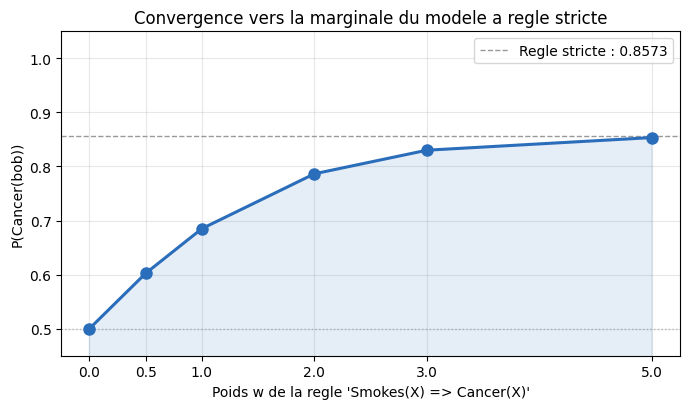

In [4]:
# --- 3. Sweep du poids : du purement statistique au quasi-logique ---
if not jvm_ready:
    print("ERREUR: JVM non demarree.")
else:
    poids_cancer = [0.0, 0.5, 1.0, 2.0, 3.0, 5.0]
    resultats = []
    for w in poids_cancer:
        mln_w = MarkovLogicNetwork()
        mln_w.add(MlnFormula(pf_sc("Smokes(anna)")))
        mln_w.add(MlnFormula(pf_sc("Friends(anna,bob)")))
        mln_w.add(MlnFormula(pf_sc("Friends(bob,carl)")))
        mln_w.add(MlnFormula(pf_sc("Smokes(X) => Cancer(X)"), JDouble(w)))
        mln_w.add(MlnFormula(pf_sc("(Smokes(X) && Friends(X,Y)) => Smokes(Y)"), JDouble(2.0)))
        rn = ApproximateNaiveMlnReasoner(JInt(200000), JInt(200000))
        p_bob = float(rn.query(mln_w, pf_sc("Cancer(bob)")))
        resultats.append((w, p_bob))

    print("Poids 'Smokes=>Cancer' | P(Cancer(bob))")
    print("-" * 42)
    for w, p in resultats:
        print(f"  w = {w:<4.1f}              | {p:.4f}")

    # Une implication stricte n'impose pas Cancer(bob) lorsque Smokes(bob)
    # reste incertain. On calcule la limite avec le constructeur strict.
    mln_strict = MarkovLogicNetwork()
    for fait in ["Smokes(anna)", "Friends(anna,bob)", "Friends(bob,carl)"]:
        mln_strict.add(MlnFormula(pf_sc(fait)))
    mln_strict.add(MlnFormula(pf_sc("Smokes(X) => Cancer(X)")))
    mln_strict.add(MlnFormula(pf_sc("(Smokes(X) && Friends(X,Y)) => Smokes(Y)"), JDouble(2.0)))
    p_strict = float(ApproximateNaiveMlnReasoner(JInt(200000), JInt(200000)).query(
        mln_strict, pf_sc("Cancer(bob)")))
    print(f"  regle stricte       | {p_strict:.4f}")

    import matplotlib.pyplot as plt
    ws = [w for w, _ in resultats]
    ps = [p for _, p in resultats]
    fig, ax = plt.subplots(figsize=(7, 4.2))
    ax.plot(ws, ps, marker="o", color="#2a6dba", lw=2.2, markersize=8, zorder=3)
    ax.fill_between(ws, ps, alpha=0.12, color="#2a6dba", zorder=2)
    ax.axhline(p_strict, color="#999", ls="--", lw=1, zorder=1,
               label=f"Regle stricte : {p_strict:.4f}")
    ax.axhline(0.5, color="#bbb", ls=":", lw=1, zorder=1)
    ax.set_xlabel("Poids w de la regle 'Smokes(X) => Cancer(X)'")
    ax.set_ylabel("P(Cancer(bob))")
    ax.set_title("Convergence vers la marginale du modele a regle stricte")
    ax.set_ylim(0.45, 1.05)
    ax.set_xticks(ws)
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

### Interprétation : le spectre logique ↔ statistique

La sortie montre que `P(Cancer(bob))` augmente lorsque le poids de la règle augmente :

| Poids de `Smokes(X) => Cancer(X)` | P(Cancer(bob)) |
|---:|---:|
| 0,0 | 0,5000 |
| 0,5 | 0,6024 |
| 1,0 | 0,6850 |
| 2,0 | 0,7865 |
| 3,0 | 0,8301 |
| 5,0 | 0,8535 |
| Règle stricte | 0,8573 |

Ces valeurs sont propres aux faits, aux autres règles et aux poids de ce réseau. La ligne pointillée représente la marginale calculée par le moteur avec la règle stricte, et non la certitude 1. La courbe illustre une convergence dans ce modèle particulier ; elle ne donne pas une valeur universelle pour tous les réseaux.

| Régime | Poids | Lecture |
|--------|-------|---------|
| Sans effet | $w = 0$ | La règle pondérée ne modifie pas la distribution. |
| Tendance | $w > 0$ | Les mondes qui satisfont la règle ont davantage de poids. |
| Limite stricte | $w \to \infty$ | Les mondes violant la règle sont exclus. |

**Attention à la distinction** : rendre `Smokes(X) => Cancer(X)` stricte n'affirme pas que Bob fume. Les mondes où Bob ne fume pas restent possibles ; sa marginale de cancer n'est donc pas nécessairement égale à 1. Le modèle strict conserve les autres règles et faits du réseau.

> **Analogie avec les solveurs SAT (NB 2)** : le reasoner naïf énumère les mondes pour ce petit domaine ; le reasoner par échantillonnage estime les marginales. La partie 5 compare leurs résultats.

## Partie 4 : Le paradoxe des exceptions — le pingouin qui ne vole pas

Une règle FOL stricte `Bird(X) => Flies(X)`, associée au fait `Bird(tweety)`, implique que Tweety vole. Si l'on ajoute aussi une règle stricte selon laquelle les pingouins ne volent pas et le fait que Tweety est un pingouin, ces hypothèses deviennent incompatibles. Cela illustre une limite de cet ensemble de règles, pas une impossibilité générale de représenter les exceptions en FOL. Les logiques non monotones proposent également d'autres façons de modéliser des règles révisables.

Pour représenter ici une tendance qui admet des exceptions, le modèle MLN ci-dessous combine :

1. `Penguin(X) => !Flies(X)` — **stricte** : les mondes où un pingouin vole sont exclus.
2. `Bird(X) => Flies(X)` — **pondérée** : les mondes satisfaisant cette règle sont favorisés sans exclure les autres.

Tweety est déclaré oiseau et pingouin. Robin est déclaré oiseau, sans fait qui établisse ou exclue `Penguin(robin)` : les deux règles doivent donc être prises en compte dans sa marginale.

In [5]:
# --- 4. Le paradoxe du pingouin : exception stricte vs regle ponderee ---
if not jvm_ready:
    print("ERREUR: JVM non demarree.")
else:
    # Signature : 1 sort, 2 constantes (tweety=pingouin, robin=oiseau)
    sig_b = FolSignature(True)
    chose = Sort("Chose"); sig_b.add(chose)
    for c in ["tweety", "robin"]:
        sig_b.add(Constant(c, chose))
    def ar(sl):
        a = ArrayList()
        for s in sl: a.add(s)
        return a
    sig_b.add(Predicate("Bird", ar([chose])))
    sig_b.add(Predicate("Penguin", ar([chose])))
    sig_b.add(Predicate("Flies", ar([chose])))
    p_b = FolParser(); p_b.setSignature(sig_b)
    def pf_b(s): return JObject(p_b.parseFormula(s), FolFormula_class)

    mln_b = MarkovLogicNetwork()
    mln_b.add(MlnFormula(pf_b("Bird(tweety)")))
    mln_b.add(MlnFormula(pf_b("Penguin(tweety)")))
    mln_b.add(MlnFormula(pf_b("Bird(robin)")))
    mln_b.add(MlnFormula(pf_b("Penguin(X) => !Flies(X)")))
    mln_b.add(MlnFormula(pf_b("Bird(X) => Flies(X)"), JDouble(2.0)))

    rb = ApproximateNaiveMlnReasoner(JInt(100000), JInt(100000))
    print("--- Paradoxe du pingouin ---")
    print("  Bird(tweety) & Penguin(tweety)  | Bird(robin) seulement")
    print("  Regle stricte Penguin=>!Flies   | Regle ponderee Bird=>Flies [w=2]")
    print()
    for atome in ["Flies(tweety)", "Flies(robin)"]:
        p = float(rb.query(mln_b, pf_b(atome)))
        print(f"  P({atome:14s}) = {p:.4f}")

    print("\nTweety est un pingouin : la regle stricte exclut son vol.")
    print("Pour Robin, Penguin(robin) n'est pas fixe : les deux regles interviennent.")

--- Paradoxe du pingouin ---
  Bird(tweety) & Penguin(tweety)  | Bird(robin) seulement
  Regle stricte Penguin=>!Flies   | Regle ponderee Bird=>Flies [w=2]

  P(Flies(tweety) ) = 0.0000
  P(Flies(robin)  ) = 0.7870

Tweety est un pingouin : la regle stricte exclut son vol.
Pour Robin, Penguin(robin) n'est pas fixe : les deux regles interviennent.


### Interprétation : règle stricte et règle pondérée

La cellule précédente produit les marginales suivantes :

| Atome | Probabilité | Lecture |
|---|---:|---|
| `Flies(tweety)` | 0,0000 | Tweety est déclaré pingouin ; les mondes où il vole sont exclus. |
| `Flies(robin)` | 0,7870 | Robin est déclaré oiseau ; son statut de pingouin n'est pas fixé. |

Tweety est explicitement déclaré pingouin : la contrainte stricte `Penguin(X) => !Flies(X)` exclut donc les mondes où il vole, même si la règle pondérée favorise le vol des oiseaux. Une formule stricte agit comme une contrainte sur les mondes admissibles, tandis qu'un poids fini module leur préférence relative.

Robin est déclaré oiseau, mais le modèle ne fixe pas `Penguin(robin)` à faux. La règle stricte concerne donc aussi les mondes où Robin est un pingouin ; la règle pondérée favorise quant à elle les mondes où un oiseau vole. La marginale affichée résulte de ces contraintes et poids ensemble, et non de la seule règle pondérée.

Une règle pondérée permet de représenter une tendance sans imposer une implication universelle stricte. On peut explorer l'effet des hypothèses en ajoutant explicitement `!Penguin(robin)` puis en comparant les marginales. La série Tweety-06 présente une autre approche des exceptions : l'argumentation défaisable, qui étudie les interactions entre arguments plutôt qu'une distribution sur les mondes.

## Partie 5 : Trois familles de reasoners MLN

Tweety propose plusieurs reasoners MLN aux compromis différents :

| Reasoner | Méthode | Portée de la comparaison |
|----------|---------|-------------------------|
| `ApproximateNaiveMlnReasoner` | Parcours d'interprétations avec budgets configurables | Utilisé ci-dessous ; les budgets couvrent les mondes du petit réseau |
| `SimpleSamplingMlnReasoner` | Échantillonnage | Résultat variable selon les tirages et paramètres |
| `AlchemyMlnReasoner` | Invocation du binaire externe Alchemy (`infer`) | Nécessite Alchemy installé ; non exécuté ici |

Le premier reasoner peut limiter les interprétations sélectionnées et conservées : les budgets sont donc importants pour interpréter son résultat. Ici, les deux limites valent 200 000, au-delà des 32 768 interprétations possibles du réseau. Le second estime une marginale par échantillonnage ; comparer plusieurs tirages aide à apprécier sa variabilité. Les temps observés comprennent les appels au moteur et ne sont pas un benchmark général.

Le wrapper `AlchemyMlnReasoner` expose `setAlchemyInferenceCommand` et appelle `infer` avec des paramètres MCMC. `SimpleMlnReasoner` est purement Java, mais son `doQuery` a levé une `NullPointerException` sur cet exemple. Le paquet contient aussi `IteratingMlnReasoner`, qui enveloppe un autre reasoner avec un budget d'itérations.

Comparons les deux reasoners Java utilisés ici sur la même requête `P(Cancer(carl))` du réseau de la partie 2.

In [6]:
# --- 5. Comparaison de deux reasoners ---
if not jvm_ready:
    print("ERREUR: JVM non demarree.")
else:
    import time
    atome = "Cancer(carl)"

    t0 = time.perf_counter()
    rn = ApproximateNaiveMlnReasoner(JInt(200000), JInt(200000))
    p_naive = float(rn.query(mln_sc, pf_sc(atome)))
    t_naive = time.perf_counter() - t0

    t0 = time.perf_counter()
    rs = SimpleSamplingMlnReasoner(0.01, 1000)
    p_samp = float(rs.query(mln_sc, pf_sc(atome)))
    t_samp = time.perf_counter() - t0

    print(f"Atome requete : P({atome})\n")
    print(f"  ApproximateNaive : {p_naive:.4f}   en {t_naive:.2f}s")
    print(f"  SimpleSampling   : {p_samp:.4f}   en {t_samp:.2f}s")
    print(f"  Ecart absolu     : {abs(p_naive - p_samp):.4f}")
    print("\nLes estimations et les temps sont a comparer sur plusieurs executions.")

Atome requete : P(Cancer(carl))

  ApproximateNaive : 0.8301   en 0.62s
  SimpleSampling   : 0.8905   en 0.02s
  Ecart absolu     : 0.0604

Les estimations et les temps sont a comparer sur plusieurs executions.


### Interprétation : comparer deux méthodes d'inférence

La cellule précédente interroge `P(Cancer(carl))`. Dans cette exécution, le reasoner naïf affiche 0,8301, contre 0,8905 pour l'échantillonnage, soit un écart absolu de 0,0604. Les temps affichés sont respectivement 0,62 s et 0,02 s ; ils dépendent de la machine et de l'exécution.

L'estimation par `SimpleSampling` dépend du tirage : sa valeur, l'écart et les temps peuvent changer à chaque exécution. Un seul résultat ne mesure pas la dispersion des estimations. Pour l'étudier, répétez les calculs et comparez leurs écarts et leurs temps avec différents budgets.

Pour ce domaine, les 15 atomes possibles correspondent à 32 768 interprétations ; les budgets du reasoner naïf permettent ici de les parcourir et de les conserver. Dans un domaine plus grand, le nombre de mondes possibles croît exponentiellement avec le nombre d'atomes et l'énumération devient coûteuse. Les budgets limités et l'échantillonnage offrent d'autres compromis, sans garantir que deux estimations concordent.

Le choix d'un reasoner dépend du domaine, de la précision recherchée et du coût acceptable ; un seul chronométrage sur ce petit réseau ne suffit pas à établir une règle générale de performance.

## Exercice 1 : Étendre le réseau social

### Contexte

Le réseau de la partie 2 contient trois personnes. Ajoutez un quatrième individu **dave**, ami de **carl**, et étudiez l'effet de ce troisième lien sur les marginales de cancer.

### Objectifs

1. Ajouter la constante `dave` à la signature.
2. Ajouter le fait strict `Friends(carl,dave)`.
3. Calculer et comparer `P(Cancer(dave))` et `P(Cancer(carl))`. Le résultat confirme-t-il une dilution à chaque saut ?

> **Indices :**

- Réutilisez la signature `sig_sc` et le parser `p_sc` de la partie 2, en ajoutant la constante et le fait.
- Reconstruisez un `MarkovLogicNetwork` avec les mêmes règles pondérées et les faits stricts.

In [7]:
# --- Exercice 1 : etendre le reseau social a un 4e individu ---
# TODO etudiant : ajoutez dave, le fait Friends(carl,dave), et requerer P(Cancer(dave))
# Etape 1 : sig_sc.add(Constant("dave", person))
# Etape 2 : construire un nouveau MLN avec le fait supplementaire Friends(carl,dave)
# Etape 3 : requerir P(Cancer(dave)) avec ApproximateNaiveMlnReasoner
print("Exercice a completer")

Exercice a completer


## Exercice 2 : Un MLN de diagnostic medical

### Contexte

On veut modeliser un raisonnement de diagnostic : certaines maladies causent certains symptomes,
mais avec une incertitude (un symptome peut avoir plusieurs causes).

### Objectifs

Construisez un MLN sur la signature `Maladie(X)`, `Symptome(X)` (predicats unaires sur un sort `Patient`)
avec :

1. Un fait strict `Maladie(grippe)` (un patient a la grippe)
2. Une règle pondérée `Maladie(X) => Symptome(X)` de poids `2.0`
3. Une règle de "symptome sans maladie" : `!Maladie(X) => !Symptome(X)` de poids `1.0`

Querir `P(Symptome(grippe))`. Faites varier le poids de la règle 2 et observez l'effet.

> **Indices :**

- Suivez le même patron que la partie 2 : `FolSignature` + `Predicate` + `MlnFormula`
- La règle `!Maladie(X) => !Symptome(X)` represente l'absence de maladie comme cause d'absence de symptome

In [8]:
# --- Exercice 2 : MLN de diagnostic medical ---
# TODO etudiant : construisez le MLN de diagnostic et requerir P(Symptome(grippe))
# Etape 1 : signature (sort Patient, predicats Maladie/1, Symptome/1, constante grippe)
# Etape 2 : MLN avec fait strict + 2 regles ponderees
# Etape 3 : sweep du poids de "Maladie=>Symptome" et afficher P(Symptome(grippe))
print("Exercice a completer")

Exercice a completer


## Exercice 3 : Approcher le modèle à règle stricte

### Contexte

Dans la partie 3, la marginale `P(Cancer(bob))` augmente avec le poids de `Smokes(X) => Cancer(X)`. Une règle stricte impose l'implication, mais pas nécessairement `Cancer(bob)` : Bob ne fume pas avec certitude.

### Objectifs

1. Calculez `P(Cancer(bob))` avec la règle stricte, construite sans poids, en conservant les autres faits et règles.
2. Calculez la même marginale pour les poids `[3, 5, 7, 10, 15, 20]`.
3. Trouvez le premier poids testé dont la marginale diffère de celle du modèle strict de moins de `0.01`.
4. Expliquez pourquoi cette convergence n'impose pas une marginale égale à 1.

> **Indices :**

- Réutilisez la construction du sweep de la partie 3.
- Comparez les marginales par leur écart absolu ; le seuil demandé dépend de la tolérance choisie.

In [9]:
# --- Exercice 3 : comparer les modèles pondérés au modèle strict ---
# TODO étudiant : calculer la marginale du modèle strict, puis celles des poids [3, 5, 7, 10, 15, 20]
# Étape 1 : reprendre la construction MLN de la partie 3 avec la règle stricte
# Étape 2 : calculer P(Cancer(bob)) pour chaque poids
# Étape 3 : identifier le premier écart absolu inférieur à 0.01
print("Exercice a completer")

Exercice a completer


***

## Résumé

Ce notebook a couvert :
- **Le concept de MLN** : une formule FOL et un poids combinent structure logique et raisonnement probabiliste.
- **Strict vs pondéré** : une règle stricte élimine les mondes qui la violent ; une règle pondérée module leur poids.
- **Friends / smokers / cancer** : les marginales d'un réseau combinent faits et règles pondérées.
- **Le spectre des poids** : comparer les marginales pour plusieurs poids à celles du modèle à règle stricte.
- **Le pingouin** : une contrainte stricte et une règle pondérée coexistent ; les faits non précisés restent à considérer.
- **Les reasoners** : comparaison de deux méthodes Java et mention de l'outil externe Alchemy.

Tweety représente un MLN par un `MarkovLogicNetwork` de `MlnFormula`, chacune enveloppant une `FolFormula` et, pour une règle pondérée, un poids.

## Prochaines étapes

- **Argumentation defeasible** : exception stricte et règle générale → [Tweety-6-Structured-Argumentation](Tweety-06-Structured-Argumentation-Python.ipynb) (ASPIC+, DeLP).
- **Argumentation probabiliste** : pondérer les arguments plutôt que les formules → [Tweety-7b-Ranking-Probabilistic](Tweety-07b-Ranking-Probabilistic-Python.ipynb).
- **Application au texte** : la série [ArgumentAnalysis](../ArgumentAnalysis/) utilise Tweety comme backend ; les MLN pourraient modéliser l'incertitude sur des faits extraits de texte.

***

**Navigation** : [← Tweety-9-Préférences](Tweety-09-Preferences-Python.ipynb) | [Index](Tweety-01-Setup-Python.ipynb) | [README](README.md)